In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px
import plotly.figure_factory as ff
import os

# Survival analysis
from lifelines import KaplanMeierFitter
from lifelines.statistics import logrank_test

# Scikit-learn utilities
from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import LabelEncoder
from sklearn.model_selection import StratifiedKFold, GridSearchCV, cross_validate
from sklearn.feature_selection import SelectKBest, f_classif, mutual_info_classif
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, f1_score, confusion_matrix, make_scorer, recall_score

from imblearn.over_sampling import SMOTE

In [3]:
class ExpressionFilter(BaseEstimator, TransformerMixin):
    """Keep genes expressed (>threshold) in ≥ min_prop of samples."""
    def __init__(self, threshold=1, min_prop=0.10):
        self.threshold = threshold
        self.min_prop = min_prop
        self.selected_indices_ = None

    def fit(self, X, y=None):
        X = pd.DataFrame(X) if not isinstance(X, pd.DataFrame) else X
        min_samples = int(self.min_prop * X.shape[0])
        mask = (X > self.threshold).sum(axis=0) >= min_samples
        self.selected_indices_ = np.where(mask)[0]
        return self

    def transform(self, X):
        if isinstance(X, pd.DataFrame):
            return X.iloc[:, self.selected_indices_]
        else:
            return X[:, self.selected_indices_]

In [ ]:
!gdown --folder 1XLgfuIG4jYS1s6AuSrkCcsPTeyZq4puP

In [5]:
tpm_bc_all_path = "ML_Model/TPM All Batch Corrected"
cliniclal_data_path = "ML_Model/Clinical Data"
tpmcpm_nbc_path = "ML_Model/TPM + CPM No Batch Correction"
cpm_bc_all_path = "ML_Model/CPM All Batch Corrected"
cpm_bc_all_new_path = "ML_Model/CPM All Batch Corrected New"
cpm_new = "ML_Model/CPM norwegian moffit"

In [6]:
label_gse_2408 = pd.read_csv(
    os.path.join(cliniclal_data_path, "GSE24080_Clinical.csv")
)

label_gse_5731 = pd.read_csv(
    os.path.join(cliniclal_data_path, "GSE57317_Clinical.csv")
)

label_gse_1364 = pd.read_csv(
    os.path.join(cliniclal_data_path, "GSE136400_Clinical.csv")
)

label_RNAseq_test = pd.read_csv(
    os.path.join(cliniclal_data_path, "pt_df_testing.csv")
)

label_norwegian = pd.read_csv(
    os.path.join(cliniclal_data_path, "norwegian_clinical.csv")
)

label_moffit= pd.read_csv(
    os.path.join(cliniclal_data_path, "moffit.csv")
)

label_RNAseq_train = pd.read_csv(
    os.path.join(cliniclal_data_path, "pt_df_training.csv")
)

In [7]:
label_gse_1364 = label_gse_1364.drop(columns=["Unnamed: 0"])
label_gse_1364.rename(columns={'Pt_ID': 'patientID'}, inplace=True)

label_gse_2408 = label_gse_2408.drop(columns=["Unnamed: 0"])
label_gse_2408.rename(columns={'PATID	': 'patientID'}, inplace=True)

label_gse_5731.rename(columns={'Accession_ID': 'patientID'}, inplace=True)

label_RNAseq_train.rename(columns={'Unnamed: 0': 'patientID'}, inplace=True)
label_RNAseq_test.rename(columns={'Unnamed: 0': 'patientID'}, inplace=True)

In [8]:
cpm_log_scaled_bc_micr = pd.read_csv(
    os.path.join(cpm_new, "logCPM_Batch_Corrected_and_scaled_with_microarrays.csv")
)

cpm_gse_2408_bc = pd.read_csv(
    os.path.join(cpm_new, "gse24080_Corrected_and_scaled_with_logCPM_rnaseq.csv")
)

cpm_gse_1364_bc = pd.read_csv(
    os.path.join(cpm_new, "gse136400_Batch_Corrected_and_scaled_with_logCPM_rnaseq.csv")
)

cpm_gse_5731_bc = pd.read_csv(
    os.path.join(cpm_new, "gse57317_Batch_Corrected_and_scaled_with_logCPM_rnaseq.csv")
)

cpm_moffit_bc = pd.read_csv(
    os.path.join(cpm_new, "moffit_Batch_Corrected_and_scaled_with_FPKM_rnaseq.csv")
)

cpm_norwegian_bc = pd.read_csv(
    os.path.join(cpm_new, "norwegian_Batch_Corrected_and_scaled_with_logCPM_rnaseq.csv")
)

In [9]:
cpm_log_bc_micr_train = cpm_log_scaled_bc_micr[label_RNAseq_train.patientID]
cpm_log_bc_micr_train.insert(0, "Gene_Name", cpm_log_scaled_bc_micr["Gene_Name"])

In [10]:
cpm_log_bc_micr_test = cpm_log_scaled_bc_micr[label_RNAseq_test.patientID]
cpm_log_bc_micr_test.insert(0, "Gene_Name", cpm_log_scaled_bc_micr["Gene_Name"])

In [11]:
common_pids = list(set(label_moffit.patientID) & set(cpm_moffit_bc.columns) - {'Gene_Name'})

cpm_moffit_bc_test = cpm_moffit_bc[common_pids + ['Gene_Name']]

cpm_moffit_bc_test = cpm_moffit_bc_test.set_index('Gene_Name')

label_moffit_filtered = label_moffit[label_moffit.patientID.isin(common_pids)]
cpm_moffit_bc_test = cpm_moffit_bc_test.reset_index().rename(columns={'index': 'Gene_Name'})

In [12]:
common_pids = list(set(label_norwegian.patientID) & set(cpm_norwegian_bc.columns) - {'Gene_Name'})

cpm_norwegian_bc_test = cpm_norwegian_bc[common_pids + ['Gene_Name']]

cpm_norwegian_bc_test = cpm_norwegian_bc_test.set_index('Gene_Name')

label_norwegian_filtered = label_norwegian[label_norwegian.patientID.isin(common_pids)]
cpm_norwegian_bc_test = cpm_norwegian_bc_test.reset_index().rename(columns={'index': 'Gene_Name'})

In [13]:
print("cpm_gse_2408_bc shape:", cpm_gse_2408_bc.shape , "label:", label_gse_2408.shape)
print("cpm_gse_5731_bc shape:", cpm_gse_5731_bc.shape , "label:", label_gse_5731.shape)
print("cpm_log_bc_micr_train shape:", cpm_log_bc_micr_train.shape , "label:", label_RNAseq_train.shape)
print("cpm_log_bc_micr_test shape:", cpm_log_bc_micr_test.shape , "label:", label_RNAseq_test.shape)
print("cpm_norwegian_bc_test.shape shape:", cpm_norwegian_bc_test.shape , "label:", label_norwegian_filtered.shape)
print("cpm_moffit_bc_test.shape shape:", cpm_moffit_bc_test.shape   , "label:", label_moffit_filtered.shape)

cpm_gse_2408_bc shape: (16831, 560) label: (559, 22)
cpm_gse_5731_bc shape: (16831, 56) label: (55, 6)
cpm_log_bc_micr_train shape: (16831, 654) label: (653, 51)
cpm_log_bc_micr_test shape: (16831, 99) label: (98, 51)
cpm_norwegian_bc_test.shape shape: (16831, 86) label: (85, 8)
cpm_moffit_bc_test.shape shape: (16831, 873) label: (872, 19)


In [14]:
def prepare_test_data(test_data, test_labels, rows_with_all_zeros):
    if 'ResponseSpeed3mo_PR' not in test_labels.columns:
        test_labels['ResponseSpeed3mo_PR'] = "Fast"

    # test_data = test_data[~rows_with_all_zeros]
    test_tpm = test_data.T
    test_tpm.index.name = 'patientID'

    test_labels['ResponseSpeed3mo_PR'] = test_labels['ResponseSpeed3mo_PR'].replace('Missing', "Fast")

    le = LabelEncoder()

    y_test = le.fit_transform(test_labels['ResponseSpeed3mo_PR'])

    return test_tpm, y_test, le, test_labels

In [15]:
def train(train_data, n_splits=5):
    rows_with_all_zeros = train_data.iloc[:, 1:].sum(axis=1) == 0
    train_data = train_data[~rows_with_all_zeros]
    gene_names = train_data["Gene_Name"].values
    train_data = train_data.drop(columns=["Gene_Name"]).T
    le_train = LabelEncoder()
    y = le_train.fit_transform(label_RNAseq_train['ResponseSpeed3mo_PR'])
    cv = StratifiedKFold(n_splits, shuffle=True, random_state=42)

    smote = SMOTE(random_state=42)
    train_data_resampled, y_resampled = smote.fit_resample(train_data, y)
    print(f"After SMOTE: Fast samples: {(y_resampled == 0).sum()}, Slow samples: {(y_resampled == 1).sum()}")

    fast_recall_scorer = make_scorer(recall_score, pos_label=0)  # Fast is class 0

    rf_pipeline = Pipeline([
        ('expr', ExpressionFilter(threshold=1, min_prop=0.10)),
        ('kbest', SelectKBest(f_classif, k=100)),
        ('clf', RandomForestClassifier(class_weight={0: 1.5, 1: 1.0}, random_state=42))
    ])

    rf_param_grid = {
        'kbest__k': [100],  
        'clf__n_estimators': [100, 300, 500], 
        'clf__max_depth': [10, 20, 30],  
        'clf__min_samples_split': [2, 4], 
        'clf__min_samples_leaf': [1, 2], 
        'clf__max_features': ['sqrt', 0.3],  
        'clf__criterion': ['gini', 'entropy', 'log_loss'],
    }

    grid_search_rf = GridSearchCV(
        rf_pipeline,
        param_grid=rf_param_grid,
        scoring={'f1_weighted': 'f1_weighted', 'fast_recall': fast_recall_scorer},
        refit='fast_recall', 
        n_jobs=-1,
        cv=cv,
        verbose=1,
        return_train_score=True
    )

    print("Fitting Random Forest Grid Search...")
    grid_search_rf.fit(train_data_resampled, y_resampled)
    print("\nBest Random Forest Parameters:", grid_search_rf.best_params_)
    print(f"Best Fast Recall Score: {grid_search_rf.best_score_:.3f}")
    print(f"Corresponding F1 Weighted Score: {grid_search_rf.cv_results_['mean_test_f1_weighted'][grid_search_rf.best_index_]:.3f}")

    thresholds = [0.3, 0.4, 0.5, 0.6]
    best_model = grid_search_rf.best_estimator_
    print("\nEvaluating thresholds during CV...")
    for thresh in thresholds:
        all_true, all_pred = [], []
        all_acc, all_f1 = [], []
        for train_idx, val_idx in cv.split(train_data_resampled, y_resampled):
            X_train, X_val = train_data_resampled.iloc[train_idx], train_data_resampled.iloc[val_idx]
            y_train, y_val = y_resampled[train_idx], y_resampled[val_idx]
            best_model.fit(X_train, y_train)
            y_prob = best_model.predict_proba(X_val)[:, 1] 
            y_pred = (y_prob >= thresh).astype(int)
            all_true.extend(y_val)
            all_pred.extend(y_pred)
            all_acc.append(accuracy_score(y_val, y_pred))
            all_f1.append(f1_score(y_val, y_pred))
        cm = confusion_matrix(all_true, all_pred)
        plt.figure(figsize=(5, 5))
        sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=le_train.classes_, yticklabels=le_train.classes_)
        plt.xlabel('Predicted')
        plt.ylabel('True')
        plt.show()
        print(f"\nThreshold {thresh}:")
        print(f"CV Accuracy: {np.mean(all_acc):.3f} ± {np.std(all_acc):.3f}")
        print(f"CV F1 Score: {np.mean(all_f1):.3f} ± {np.std(all_f1):.3f}")

    return train_data, y, rf_pipeline, grid_search_rf, le_train, rows_with_all_zeros, gene_names

After SMOTE: Fast samples: 397, Slow samples: 397
Fitting Random Forest Grid Search...
Fitting 5 folds for each of 216 candidates, totalling 1080 fits

Best Random Forest Parameters: {'clf__criterion': 'entropy', 'clf__max_depth': 10, 'clf__max_features': 'sqrt', 'clf__min_samples_leaf': 2, 'clf__min_samples_split': 2, 'clf__n_estimators': 300, 'kbest__k': 100}
Best Fast Recall Score: 0.756
Corresponding F1 Weighted Score: 0.683

Evaluating thresholds during CV...


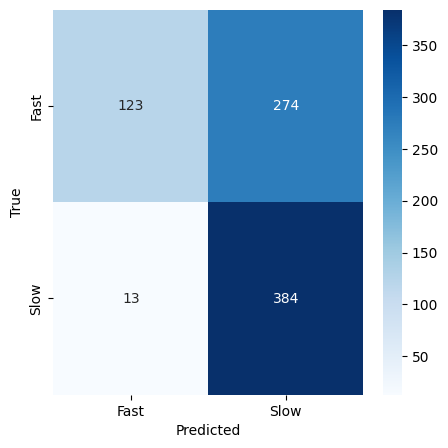


Threshold 0.3:
CV Accuracy: 0.639 ± 0.026
CV F1 Score: 0.728 ± 0.016


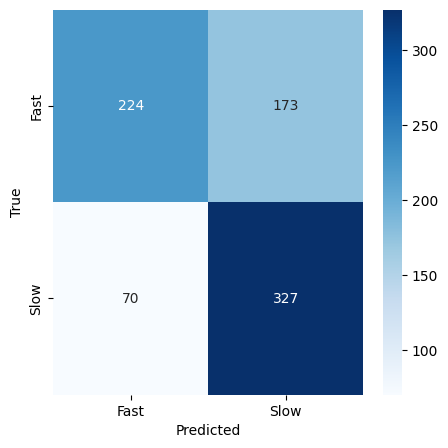


Threshold 0.4:
CV Accuracy: 0.694 ± 0.029
CV F1 Score: 0.729 ± 0.025


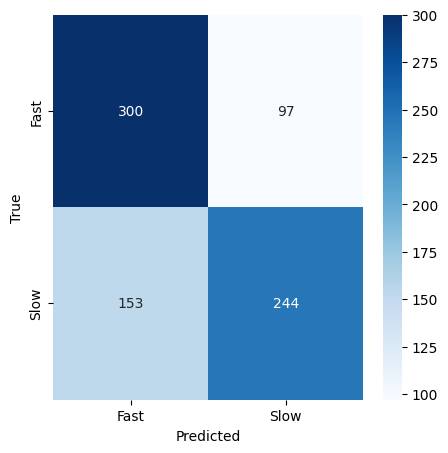


Threshold 0.5:
CV Accuracy: 0.685 ± 0.043
CV F1 Score: 0.659 ± 0.060


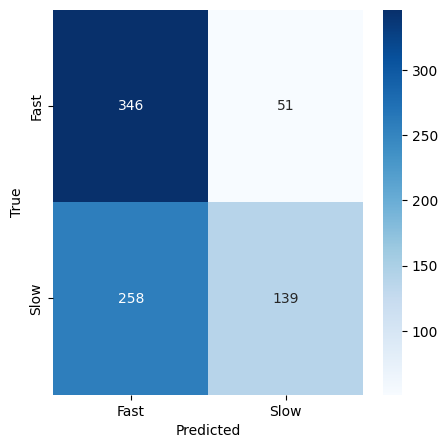


Threshold 0.6:
CV Accuracy: 0.611 ± 0.038
CV F1 Score: 0.469 ± 0.076


In [16]:
train_data, y, rf_pipeline, grid_search_rf, le_train, rows_with_all_zeros, gene_names = train(cpm_log_bc_micr_train, n_splits=5)

In [17]:
gse_1364_test, gse_1364_y_test, gse_1364_le, gse_1364_test_labels = prepare_test_data(cpm_gse_1364_bc,label_gse_1364 ,  rows_with_all_zeros)
gse_2408_test, gse_2408_y_test, gse_2408_le, gse_2408_test_labels = prepare_test_data(cpm_gse_2408_bc,label_gse_2408 ,  rows_with_all_zeros)
gse_5731_test, gse_5731_y_test, gse_5731_le, gse_5731_test_labels = prepare_test_data(cpm_gse_5731_bc,label_gse_5731 ,  rows_with_all_zeros)
rnaseq_test, rnaseq_y_test, rnaseq_le, rnaseq_test_labels = prepare_test_data(cpm_log_bc_micr_test, label_RNAseq_test,  rows_with_all_zeros)
norwegian_test, norwegian_y_test, norwegian_le, norwegian_test_labels = prepare_test_data(cpm_norwegian_bc_test, label_norwegian_filtered, rows_with_all_zeros)
moffit_test, moffit_y_test, moffit_le, moffit_test_labels = prepare_test_data(cpm_moffit_bc_test, label_moffit_filtered, rows_with_all_zeros)

In [18]:
gse_1364_test_labels.rename(columns={'patientID': 'ID'}, inplace=True)
gse_1364_test_labels.rename(columns={'Geo_Accession': 'patientID'}, inplace=True)
#1364
gse_1364_test = gse_1364_test[gse_1364_test.index != 'Unnamed: 0']

#2408
gse_2408_test = gse_2408_test[gse_2408_test.index != 'Gene_Name']
gse_2408_test_labels.rename(columns={'PATID': 'patientID'}, inplace=True)
gse_2408_test_labels['patientID'] = gse_2408_test_labels['patientID'].str.replace('.gz', '', regex=False)

gse_5731_test = gse_5731_test[gse_5731_test.index != 'Gene_Name']

rnaseq_test = rnaseq_test[rnaseq_test.index != 'Gene_Name']

moffit_test = moffit_test[moffit_test.index != 'Gene_Name']

norwegian_test = norwegian_test[norwegian_test.index != 'Gene_Name']

In [19]:
def km_plot(df, time_col, event_col, group_col, title, label_encoder):
    kmf = KaplanMeierFitter()
    plt.figure(figsize=(7, 5))
    for grp, color in zip(label_encoder.classes_, ['tab:red', 'tab:blue']):
        mask = df[group_col] == grp
        if mask.sum() == 0:
            continue
        kmf.fit(df.loc[mask, time_col], df.loc[mask, event_col], label=grp)
        kmf.plot_survival_function(ci_show=True, color=color)
    group0 = df[group_col] == label_encoder.classes_[0]
    group1 = df[group_col] == label_encoder.classes_[1]
    if group0.sum() > 0 and group1.sum() > 0:
        res = logrank_test(
            df.loc[group0, time_col],
            df.loc[group1, time_col],
            df.loc[group0, event_col],
            df.loc[group1, event_col]
        )
        plt.title(f"{title}\nlog-rank p = {res.p_value:.4g}")
    else:
        plt.title(f"{title}\nlog-rank p = N/A (insufficient data)")
    plt.xlabel('Time (days)')
    plt.ylabel('Survival Probability')
    plt.grid(ls='--', alpha=0.3)
    plt.tight_layout()
    plt.show()

In [20]:
def prepare_plot(rf_pipeline, grid_search_rf, train_data, y, test_data, y_test, test_labels, le_train, gene_names, dataset_name="", thresholds=None):
    test_results = []
    test_labels = test_labels.set_index('patientID')
    model_pipeline = grid_search_rf.best_estimator_
    model_pipeline.fit(train_data, y)

    current_features = gene_names
    expr_filter = model_pipeline.named_steps['expr']
    current_features = current_features[expr_filter.selected_indices_]
    kbest = model_pipeline.named_steps['kbest']
    selected_features_mask = kbest.get_support()
    selected_features = current_features[selected_features_mask].tolist()

    classifier = model_pipeline.named_steps['clf']
    importances = classifier.feature_importances_
    min_importance = np.nanmin(importances)
    max_importance = np.nanmax(importances)
    normalized_importances = (importances - min_importance) / (max_importance - min_importance) if max_importance > min_importance else np.zeros_like(importances)

    features_df = pd.DataFrame({
        'Selected_Features': selected_features,
        'Normalized_Importance': normalized_importances
    })
    features_df = features_df.sort_values(by='Normalized_Importance', ascending=False)  
    features_df.to_csv(f'selected_features_Random_Forest_Tuned_{dataset_name}.csv', index=False)

    y_prob = model_pipeline.predict_proba(test_data)[:, 1] 

    for thresh in thresholds:
        y_pred = (y_prob >= thresh).astype(int)
        print(f"Random Forest (Tuned) - {dataset_name} (Threshold {thresh}):")
        print(y_pred)
        acc = accuracy_score(y_test, y_pred)
        f1 = f1_score(y_test, y_pred)
        test_results.append({
            'Model': f'Random Forest (Tuned, Threshold {thresh})',
            'Test Accuracy': acc,
            'Test F1 Score': f1
        })
        pred_column_name = f"ML_Result_Random_Forest_Tuned_{thresh}"
        test_labels.loc[test_data.index, pred_column_name] = le_train.inverse_transform(y_pred)

    survival_cols = ['OS_Time', 'OS_Censor']
    if 'PFS_Time' in test_labels.columns and 'PFS_Censor' in test_labels.columns:
        survival_cols.extend(['PFS_Time', 'PFS_Censor'])
    for col in survival_cols:
        test_labels[col] = pd.to_numeric(test_labels[col], errors='coerce')

    test_clin = test_labels.dropna(subset=['OS_Time', 'OS_Censor'], how='all')
    if 'PFS_Time' in test_labels.columns and 'PFS_Censor' in test_labels.columns:
        test_clin = test_clin.dropna(subset=['PFS_Time', 'PFS_Censor'], how='all')

    test_results_df = pd.DataFrame(test_results)
    return test_clin, test_results_df

def plot_survival_curves(test_results_df, test_clin, le_train, dataset_name="", thresholds=None):
    n_thresholds = len(thresholds)
    
    fig, axes = plt.subplots(2, n_thresholds, figsize=(5 * n_thresholds, 8), sharey=True)
    if n_thresholds == 1:
        axes = np.array([[axes[0]], [axes[1]]]) 
    elif n_thresholds > 1:
        axes = np.array(axes)  

    for idx, thresh in enumerate(thresholds):
        model_name = f'Random Forest (Tuned, Threshold {thresh})'
        pred_col = f"ML_Result_Random_Forest_Tuned_{thresh}"
        
        if pred_col in test_clin.columns:
            # OS Plot
            os_valid = test_clin.dropna(subset=['OS_Time', 'OS_Censor'])
            if not os_valid.empty:
                ax = axes[0, idx]
                kmf = KaplanMeierFitter()
                for grp, color in zip(le_train.classes_, ['tab:red', 'tab:blue']):
                    mask = os_valid[pred_col] == grp
                    if mask.sum() == 0:
                        print(f"Warning: No data for group {grp} in {pred_col} (OS, {dataset_name})")
                        continue
                    kmf.fit(os_valid.loc[mask, 'OS_Time'], os_valid.loc[mask, 'OS_Censor'], label=grp)
                    kmf.plot_survival_function(ci_show=True, color=color, ax=ax)
                group0 = os_valid[pred_col] == le_train.classes_[0]
                group1 = os_valid[pred_col] == le_train.classes_[1]
                if group0.sum() > 0 and group1.sum() > 0:
                    res = logrank_test(
                        os_valid.loc[group0, 'OS_Time'],
                        os_valid.loc[group1, 'OS_Time'],
                        os_valid.loc[group0, 'OS_Censor'],
                        os_valid.loc[group1, 'OS_Censor']
                    )
                    ax.set_title(f"OS (Threshold {thresh})\nlog-rank p = {res.p_value:.4g}")
                else:
                    ax.set_title(f"OS (Threshold {thresh})\nlog-rank p = N/A")
                ax.set_xlabel('Time (days)')
                ax.set_ylabel('Survival Probability')
                ax.grid(ls='--', alpha=0.3)

            if 'PFS_Time' in test_clin.columns and 'PFS_Censor' in test_clin.columns:
                pfs_valid = test_clin.dropna(subset=['PFS_Time', 'PFS_Censor'])
                if not pfs_valid.empty:
                    ax = axes[1, idx]
                    kmf = KaplanMeierFitter()
                    for grp, color in zip(le_train.classes_, ['tab:red', 'tab:blue']):
                        mask = pfs_valid[pred_col] == grp
                        if mask.sum() == 0:
                            print(f"Warning: No data for group {grp} in {pred_col} (PFS, {dataset_name})")
                            continue
                        kmf.fit(pfs_valid.loc[mask, 'PFS_Time'], pfs_valid.loc[mask, 'PFS_Censor'], label=grp)
                        kmf.plot_survival_function(ci_show=True, color=color, ax=ax)
                    group0 = pfs_valid[pred_col] == le_train.classes_[0]
                    group1 = pfs_valid[pred_col] == le_train.classes_[1]
                    if group0.sum() > 0 and group1.sum() > 0:
                        res = logrank_test(
                            pfs_valid.loc[group0, 'PFS_Time'],
                            pfs_valid.loc[group1, 'PFS_Time'],
                            pfs_valid.loc[group0, 'PFS_Censor'],
                            pfs_valid.loc[group1, 'PFS_Censor']
                        )
                        ax.set_title(f"PFS (Threshold {thresh})\nlog-rank p = {res.p_value:.4g}")
                    else:
                        ax.set_title(f"PFS (Threshold {thresh})\nlog-rank p = N/A")
                    ax.set_xlabel('Time (days)')
                    ax.set_ylabel('Survival Probability')
                    ax.grid(ls='--', alpha=0.3)
                else:
                    axes[1, idx].set_title(f"PFS (Threshold {thresh})\nNo valid PFS data")
                    axes[1, idx].set_xlabel('Time (days)')
                    axes[1, idx].set_ylabel('Survival Probability')
                    axes[1, idx].grid(ls='--', alpha=0.3)
            else:
                axes[1, idx].set_title(f"PFS (Threshold {thresh})\nPFS data not available")
                axes[1, idx].set_xlabel('Time (days)')
                axes[1, idx].set_ylabel('Survival Probability')
                axes[1, idx].grid(ls='--', alpha=0.3)

    plt.suptitle(f"Survival Curves for {dataset_name}", fontsize=16)
    plt.tight_layout(rect=[0, 0, 1, 0.95])
    plt.show()

In [21]:
thresholds = [0.5]

Random Forest (Tuned) - Norwegian (Threshold 0.5):
[1 0 1 1 1 1 0 0 1 1 1 1 1 1 0 1 0 0 1 1 1 0 1 1 0 0 0 1 0 1 1 1 0 0 0 1 0
 1 1 1 1 1 0 0 1 1 1 1 1 1 1 1 1 1 1 1 1 0 1 1 1 1 1 1 0 0 1 1 1 1 1 1 1 1
 1 1 1 1 1 1 1 1 0 1 1]


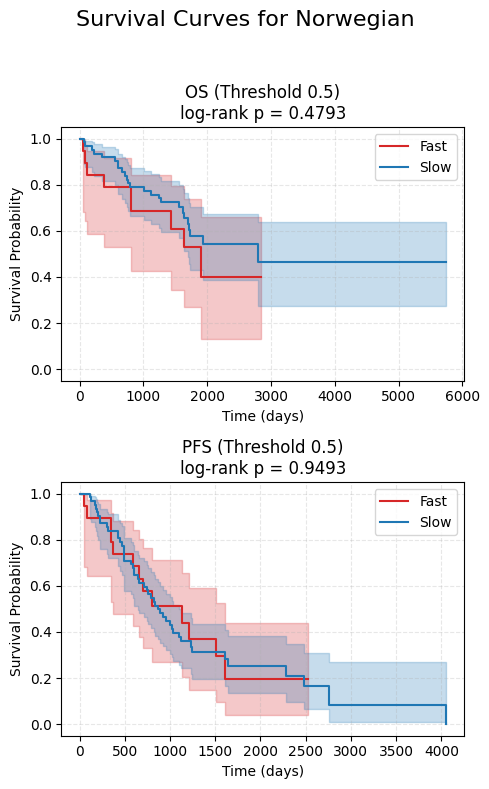

In [22]:
test_celin_norwegian, test_results_norwegian = prepare_plot(rf_pipeline, grid_search_rf, train_data, y, norwegian_test, norwegian_y_test, norwegian_test_labels, le_train, gene_names, "Norwegian", thresholds=thresholds)
plot_survival_curves(test_results_norwegian, test_celin_norwegian, le_train, dataset_name="Norwegian", thresholds=thresholds)

In [23]:
test_celin_moffit, test_results_moffit = prepare_plot(
    rf_pipeline, grid_search_rf, train_data, y, moffit_test, moffit_y_test, moffit_test_labels, le_train, gene_names, dataset_name="Moffit", thresholds=thresholds
)
plot_survival_curves(test_results_moffit, test_celin_moffit, le_train, dataset_name="Moffit", thresholds=thresholds)

Random Forest (Tuned) - Moffit (Threshold 0.5):
[1 1 1 0 1 0 1 0 0 1 1 1 1 1 1 1 1 1 1 1 0 1 1 0 1 0 1 1 0 1 1 1 1 1 0 1 1
 1 1 1 0 1 1 1 0 1 1 1 1 0 1 0 1 1 1 1 1 1 0 1 0 1 0 1 1 0 1 1 1 1 0 0 1 0
 0 1 0 0 1 0 0 1 1 0 1 1 0 1 0 0 1 1 0 1 0 1 0 1 1 1 1 1 1 1 1 0 1 0 1 0 1
 0 1 1 0 1 0 1 1 0 1 1 0 1 1 1 1 1 0 1 0 1 1 0 1 1 1 1 1 0 0 0 1 0 0 1 0 1
 1 1 1 0 1 1 0 1 1 1 1 1 0 1 1 0 1 0 0 0 1 1 0 0 1 0 1 1 1 1 1 1 1 0 0 1 1
 1 0 1 1 0 1 0 1 1 1 1 1 0 1 1 0 1 0 0 1 1 1 1 1 1 1 1 0 0 0 0 1 1 1 0 1 1
 1 1 0 0 0 1 0 1 0 1 1 1 1 1 1 1 1 1 1 0 1 0 0 0 0 0 0 1 1 1 1 1 0 1 1 1 0
 1 1 0 1 0 0 1 0 0 0 1 1 1 0 0 1 1 0 0 1 1 0 1 0 1 1 1 1 0 1 0 1 1 0 0 0 0
 1 1 0 1 1 1 1 1 1 0 1 1 1 1 1 1 0 0 1 1 0 1 1 1 1 0 0 1 1 1 0 1 1 1 0 1 1
 1 1 1 0 1 0 1 1 1 0 0 1 1 1 1 1 1 1 1 1 0 0 1 1 0 1 1 0 0 1 1 0 1 0 0 1 0
 0 0 1 1 1 1 0 1 1 1 1 1 1 0 0 0 0 1 0 0 1 1 1 1 0 1 0 1 0 0 1 0 0 0 0 1 0
 0 0 0 1 1 1 0 1 0 0 1 0 0 1 1 1 0 1 0 1 1 0 1 1 0 1 1 1 1 0 1 0 1 1 0 0 1
 1 0 1 1 1 0 0 1 1 1 0 1 1 1 1 1 1 1 1 0 0 1 1 0 0 0

KeyError: 'OS_Time'

In [24]:
gse_1364_test = gse_1364_test[gse_1364_test.index != 'Gene_Name']

Random Forest (Tuned) - GSE1364 (Threshold 0.5):
[1 1 1 1 1 1 1 1 1 0 1 0 1 1 1 1 1 1 1 1 0 1 1 1 1 1 1 1 1 1 1 1 1 1 0 0 1
 1 0 1 1 1 1 1 0 1 0 0 1 1 0 0 0 0 1 0 0 0 1 1 0 1 0 1 1 1 1 1 1 1 1 1 1 1
 1 0 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 0 0 1 1 1 1 1 1 1 1 1 1 0 1
 1 1 1 1 1 1 1 0 0 1 1 1 1 1 1 1 1 1 1 1 1 1 1 0 1 1 1 1 1 1 1 1 1 1 1 1 1
 1 1 1 1 1 1 1 1 1 1 1 1 1 0 1 1 1 1 1 1 1 1 1 1 1 1 0 1 1 1 1 1 1 1 1 1 1
 1 1 1 1 1 1 1 1 1 1 0 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 0 0 1 1 1 1 1 1 1
 1 1 1 1 1 1 1 1 1 1 0 1 1 1 1 1 1 1 1 1 1 1 1 0 1 0 1 1 1 1 1 1 0 1 1 1 1
 1 1 1 1 1 0 1 0 0 0 1 1 1 1 1 1 1 0 1 1 1 1 0 1 1 1 1 1 1]


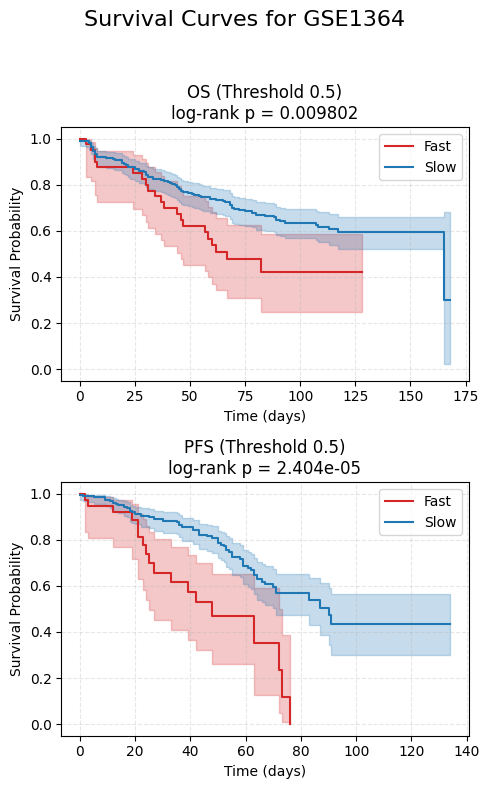

In [25]:
test_clin_gse_1364, test_results_df_gse_1364 = prepare_plot(rf_pipeline, grid_search_rf, train_data, y, gse_1364_test, gse_1364_y_test, gse_1364_test_labels, le_train, gene_names, "GSE1364", thresholds=thresholds)
plot_survival_curves(test_results_df_gse_1364, test_clin_gse_1364, le_train, dataset_name="GSE1364", thresholds=thresholds)

2408

Random Forest (Tuned) - GSE2408 (Threshold 0.5):
[1 1 1 1 0 1 1 1 1 1 1 0 1 1 1 1 0 1 0 1 1 0 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1
 1 1 1 1 1 1 1 1 1 0 1 1 1 1 1 1 1 1 1 1 1 1 0 1 1 1 1 1 1 1 1 0 0 1 1 1 1
 1 1 1 1 0 1 1 0 1 1 1 1 1 1 1 1 0 1 1 1 1 1 1 1 1 1 1 1 1 1 1 0 1 1 1 1 1
 1 1 0 1 1 1 1 0 1 1 1 1 1 1 1 1 1 1 1 1 0 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1
 1 1 1 1 1 1 1 1 1 1 1 1 0 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 0 1 1 1 1
 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 0 0 1 0 1 1 1 1 1 1 1 1 0 1 0 0 1 1 1 1
 1 1 1 1 1 0 1 0 1 1 1 1 1 1 1 1 1 1 1 1 1 1 0 1 1 1 1 1 1 0 1 0 0 1 1 0 1
 1 0 1 0 1 1 0 1 1 1 1 1 1 1 1 1 1 1 1 1 1 0 1 1 1 1 0 0 1 0 0 0 1 1 1 1 0
 0 1 1 1 1 1 1 0 1 1 1 1 1 1 1 1 1 0 1 0 1 0 1 1 1 1 1 0 1 1 1 0 1 1 1 1 1
 1 0 1 1 1 1 1 1 0 1 1 1 1 1 1 1 1 0 1 0 1 1 1 1 1 1 1 1 1 1 1 1 1 0 1 1 0
 1 1 1 0 0 1 0 0 1 1 0 1 1 0 1 0 1 0 0 1 0 1 1 1 1 0 1 1 1 1 0 1 0 1 1 1 1
 1 1 1 1 1 1 1 1 1 1 1 1 0 0 1 1 1 1 1 1 1 1 1 1 0 0 1 1 1 1 1 1 1 1 1 1 1
 1 1 1 1 0 1 1 1 1 0 1 1 1 1 1 1 1 1 1 0 1 1 1 0 1 

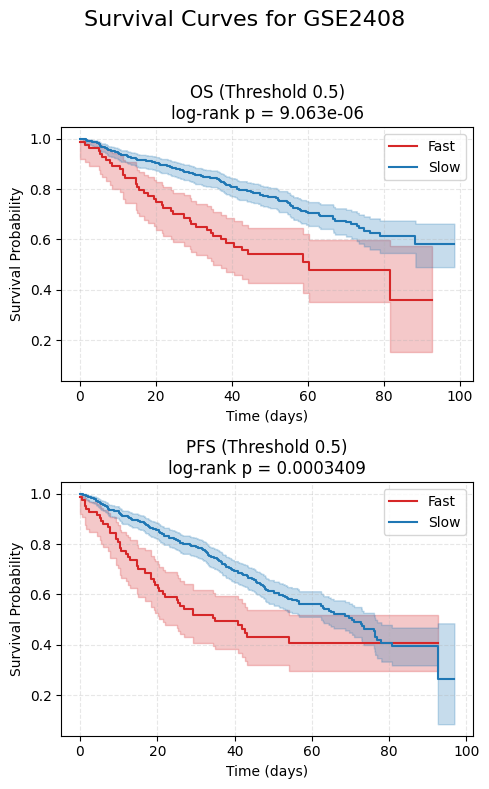

In [26]:

test_clin_gse_2408, test_results_df_gse_2408 = prepare_plot(rf_pipeline, grid_search_rf, train_data, y, gse_2408_test, gse_2408_y_test, gse_2408_test_labels, le_train, gene_names, "GSE2408",thresholds=thresholds)
plot_survival_curves(test_results_df_gse_2408, test_clin_gse_2408, le_train, dataset_name="GSE2408", thresholds=thresholds)


5731

Random Forest (Tuned) - GSE5731 (Threshold 0.5):
[1 1 0 0 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 0 1 1 1 1 0 0 1 0 1 0 1 0
 0 1 0 1 1 1 1 1 1 1 1 0 1 1 1 1 1 0]


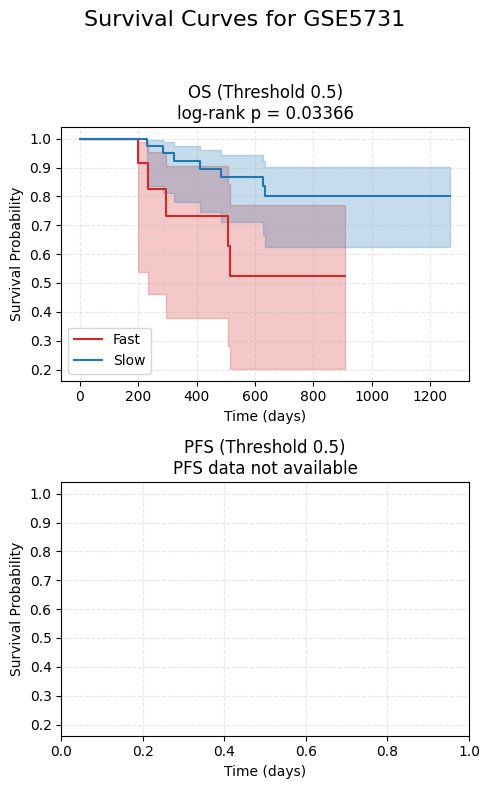

In [27]:
test_clin_gse_5731, test_results_df_gse_5731 = prepare_plot(rf_pipeline, grid_search_rf, train_data, y, gse_5731_test, gse_5731_y_test, gse_5731_test_labels, le_train, gene_names, "GSE5731", thresholds=thresholds)
plot_survival_curves(test_results_df_gse_5731, test_clin_gse_5731, le_train, dataset_name="GSE5731", thresholds=thresholds)

rnaseq

Random Forest (Tuned) - RNAseq (Threshold 0.5):
[1 1 1 1 1 1 1 1 1 0 1 1 1 1 1 1 1 1 0 1 1 1 0 1 1 0 1 1 1 0 1 1 1 1 1 1 1
 1 0 1 0 1 1 1 1 1 1 1 0 0 0 1 0 1 1 1 0 1 1 0 0 1 0 1 1 1 0 1 1 1 1 0 1 1
 1 1 1 1 0 0 0 0 0 1 0 0 0 0 1 1 0 0 0 0 0 0 0 0]


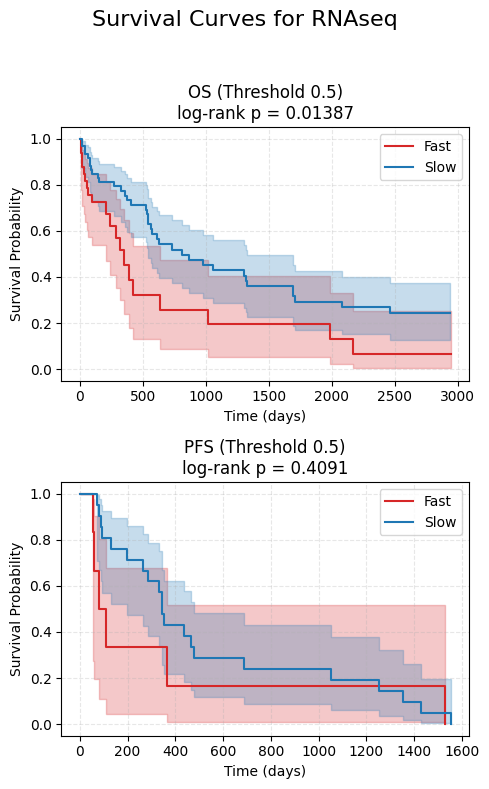

In [28]:
test_clin_rnaseq, test_results_df_rnaseq = prepare_plot(rf_pipeline, grid_search_rf, train_data, y, rnaseq_test, rnaseq_y_test, rnaseq_test_labels, le_train, gene_names, "RNAseq", thresholds=thresholds)
plot_survival_curves(test_results_df_rnaseq, test_clin_rnaseq, le_train, dataset_name="RNAseq", thresholds=thresholds)